# CSCI 3003 - Data Visualization

## Lab 3: Transforming, Summarizing, and Reshaping Data

**Name:** Steve Tatsiguia  
**Date:** 2026-09-10  
**Version:** Student notebook

> Add your name and date before submitting.


## Purpose and learning objectives

Visualizations depend on the table supplied to the plotting function. This lab develops the pandas skills needed to turn a raw table into an analysis-ready table. By the end, you should be able to:

- Filter rows using one or more conditions.
- Sort rows by one or more columns.
- Create derived columns from existing variables.
- Group observations and calculate useful summaries.
- Connect pandas operations with readable method chains.
- Reshape summaries with `pivot_table()` and `melt()`.
- Create quick plots from prepared tables and explain what they reveal.

We will use `loan50.csv` throughout so that each new operation builds on a familiar dataset.


## I. Import packages and load the data

Reuse the import and file-loading workflow from Labs 1 and 2. The configured notebook working directory already contains `loan50.csv`.


In [45]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [46]:
loan_file = Path("loan50.csv")
loan_file.exists()

True

In [47]:
loans = pd.read_csv(loan_file)
loans.shape

(50, 18)

In [48]:
loans.head()

,state,emp_length,term,homeownership,annual_income,verified_income,debt_to_income,total_credit_limit,total_credit_utilized,num_cc_carrying_balance,loan_purpose,loan_amount,grade,interest_rate,public_record_bankrupt,loan_status,has_second_income,total_income
0,NJ,3.0,60,rent,59000,Not Verified,0.557525,95131,32894,8,debt_consolidation,22000,B,10.90,0,Current,False,59000
1,CA,10.0,36,rent,60000,Not Verified,1.305683,51929,78341,2,credit_card,6000,B,9.92,1,Current,False,60000
2,SC,NaN,36,mortgage,75000,Verified,1.056280,301373,79221,14,debt_consolidation,25000,E,26.30,0,Current,False,75000
3,CA,0.0,36,rent,75000,Not Verified,0.574347,59890,43076,10,credit_card,6000,B,9.92,0,Current,False,75000
4,OH,4.0,60,mortgage,254000,Not Verified,0.238150,422619,60490,2,home_improvement,25000,B,9.43,0,Current,False,254000


**Question 1:** What does one row represent? Which three columns would you use to investigate the total cost of a loan?

**Loan formula hint:** For a fixed-rate loan with equal monthly payments, let $P$ be `loan_amount`, $r$ be the monthly interest rate (`interest_rate / 1200`), and $n$ be `term` in months. The monthly payment is

$$M = P\left(\frac{r(1+r)^n}{(1+r)^n-1}\right).$$

The total amount paid is $M \times n$, and the total interest paid is $(M \times n) - P$. This calculation assumes no additional fees.

**Answer:** one row represent a loan. The three columns I would use to investigate the total cost of a loan are loan_amount, interest_rate, and term.



## II. Filter rows

Filtering keeps rows that satisfy a condition. The comparison below returns `True` or `False` for every row.


In [49]:
large_loan_condition = loans["loan_amount"] >= 15000
large_loan_condition.head()

0     True
1    False
2     True
3    False
4     True
Name: loan_amount, dtype: bool

Place the condition inside square brackets to retain only rows where the condition is `True`.


In [50]:
large_loans = loans[large_loan_condition]
large_loans[["loan_amount", "grade", "interest_rate"]].head()

,loan_amount,grade,interest_rate
0,22000,B,10.90
2,25000,E,26.30
4,25000,B,9.43
9,18500,C,12.62
10,17000,D,17.09


### Combine conditions

Use `&` for **and** and `|` for **or**. Put each complete comparison in parentheses. The following filter keeps loans that are both large and grade A or B.


In [51]:
large_lower_rate_loans = loans[
    (loans["loan_amount"] >= 15000) & (loans["grade"].isin(["A", "B"]))
]

large_lower_rate_loans[["loan_amount", "grade", "interest_rate"]].head()

,loan_amount,grade,interest_rate
0,22000,B,10.90
4,25000,B,9.43
12,16000,A,7.35
13,16500,A,5.31
17,18200,B,10.42


`.isin([...])` checks whether each value appears in a list. It is clearer than writing several equality comparisons for the same column.

**Question 2:** Filter the data to loans used for either `credit_card` or `home_improvement` whose interest rate is at least 10%. Display `loan_purpose`, `loan_amount`, `grade`, and `interest_rate`. How many rows satisfy both conditions?

Use the next cell for your code.


In [52]:
credit_home_loans = loans[
    (loans["loan_purpose"].isin(["credit_card", "home_improvement"])) &
    (loans["interest_rate"] >= 10)
]

credit_home_loans[["loan_purpose", "loan_amount", "grade", "interest_rate"]]

,loan_purpose,loan_amount,grade,interest_rate
15,credit_card,29400,E,24.85
28,credit_card,35000,B,11.98
34,credit_card,4400,D,18.45
41,credit_card,15000,C,16.02
45,home_improvement,6000,B,10.42


**Answer:** 5 rows satisfy both conditions.



<br><br><br>

### Check your work

Compare your code with one valid solution below. Your variable name may differ.


In [53]:
selected_purpose_loans = loans[
    (loans["loan_purpose"].isin(["credit_card", "home_improvement"]))
    & (loans["interest_rate"] >= 10)
]

selected_purpose_loans[["loan_purpose", "loan_amount", "grade", "interest_rate"]]

,loan_purpose,loan_amount,grade,interest_rate
15,credit_card,29400,E,24.85
28,credit_card,35000,B,11.98
34,credit_card,4400,D,18.45
41,credit_card,15000,C,16.02
45,home_improvement,6000,B,10.42


## III. Sort rows

`.sort_values()` rearranges rows without changing their values.

- `by="column_name"` identifies the sorting column.
- `ascending=False` places the largest values first.


In [54]:
loans_sorted_by_rate = loans.sort_values(
    by="interest_rate",
    ascending=False,
)

loans_sorted_by_rate[["grade", "interest_rate", "loan_amount"]].head(10)

,grade,interest_rate,loan_amount
2,E,26.30,25000
15,E,24.85,29400
46,D,21.45,30000
21,D,20.00,40000
19,D,19.42,18000
34,D,18.45,4400
16,D,18.06,13500
6,D,17.09,3000
10,D,17.09,17000
35,D,17.09,7000


To break ties, provide lists of column names and directions. This example sorts by grade from A to E, then by loan amount from largest to smallest within each grade.


In [55]:
loans_sorted_by_grade_amount = loans.sort_values(
    by=["grade", "loan_amount"],
    ascending=[True, False],
)

loans_sorted_by_grade_amount[["grade", "loan_amount", "interest_rate"]].head(10)

,grade,loan_amount,interest_rate
38,A,35000,6.71
33,A,30000,7.35
36,A,25000,7.96
25,A,20000,5.32
13,A,16500,5.31
12,A,16000,7.35
49,A,15000,6.08
7,A,14500,6.08
11,A,12000,5.31
8,A,10000,7.97


**Question 3:** Sort the loans from highest to lowest annual income. Display `annual_income`, `loan_amount`, `loan_purpose`, and `homeownership` for the first eight rows. Describe one observation that stands out.

Use the next cell for your code.


In [56]:
loans_sorted_by_income = loans.sort_values(
    by="annual_income",
    ascending=False,
)

loans_sorted_by_income[
    ["annual_income", "loan_amount", "loan_purpose", "homeownership"]
].head(8)

,annual_income,loan_amount,loan_purpose,homeownership
38,325000,35000,credit_card,mortgage
4,254000,25000,home_improvement,mortgage
28,245000,35000,credit_card,mortgage
23,185000,15000,credit_card,rent
40,160000,38500,debt_consolidation,mortgage
11,120000,12000,credit_card,mortgage
30,116000,13125,debt_consolidation,rent
13,105000,16500,home_improvement,mortgage


**Answer:** One thing that stands out is that the borrower with the highest annual income earns $254,000 and has a mortgage.




## IV. Create derived columns

A **derived column** is calculated from one or more existing columns. It can express a quantity that better matches the question.

The next cell calculates what percentage of each borrower's total credit limit is currently utilized.


In [57]:
loans["credit_utilization_percent"] = (
    loans["total_credit_utilized"] / loans["total_credit_limit"] * 100
)

loans[
    ["total_credit_utilized", "total_credit_limit", "credit_utilization_percent"]
].head()

,total_credit_utilized,total_credit_limit,credit_utilization_percent
0,32894,95131,34.577582
1,78341,51929,150.861754
2,79221,301373,26.286695
3,43076,59890,71.925196
4,60490,422619,14.313128


The parentheses allow the calculation to span several readable lines. The new column becomes part of `loans`.

**Question 4:** Create `loan_to_income_percent`, defined as `loan_amount / annual_income * 100`. Display the three columns involved and explain what a value of 20 would mean.

Use the next cell for your code.


In [58]:
loans["loan_to_income_percent"] = (
    loans["loan_amount"] / loans["annual_income"] * 100
)

loans[
    ["loan_amount", "annual_income", "loan_to_income_percent"]
].head()

,loan_amount,annual_income,loan_to_income_percent
0,22000,59000,37.288136
1,6000,60000,10.000000
2,25000,75000,33.333333
3,6000,75000,8.000000
4,25000,254000,9.842520


**Answer:** A value of 20 means the loan amount is equal to 20% of the borrower’s annual income.




### Use `.assign()` without changing the original DataFrame

`.assign()` returns a DataFrame with one or more derived columns. It is useful inside a method chain because it passes the updated table to the next operation.


In [59]:
loans_with_income_gap = loans.assign(
    income_gap=loans["total_income"] - loans["annual_income"]
)

loans_with_income_gap.head()

,state,emp_length,term,homeownership,annual_income,verified_income,debt_to_income,total_credit_limit,total_credit_utilized,num_cc_carrying_balance,...,loan_amount,grade,interest_rate,public_record_bankrupt,loan_status,has_second_income,total_income,credit_utilization_percent,loan_to_income_percent,income_gap
0,NJ,3.0,60,rent,59000,Not Verified,0.557525,95131,32894,8,...,22000,B,10.90,0,Current,False,59000,34.577582,37.288136,0
1,CA,10.0,36,rent,60000,Not Verified,1.305683,51929,78341,2,...,6000,B,9.92,1,Current,False,60000,150.861754,10.000000,0
2,SC,NaN,36,mortgage,75000,Verified,1.056280,301373,79221,14,...,25000,E,26.30,0,Current,False,75000,26.286695,33.333333,0
3,CA,0.0,36,rent,75000,Not Verified,0.574347,59890,43076,10,...,6000,B,9.92,0,Current,False,75000,71.925196,8.000000,0
4,OH,4.0,60,mortgage,254000,Not Verified,0.238150,422619,60490,2,...,25000,B,9.43,0,Current,False,254000,14.313128,9.842520,0


**Question 5a:** What do you notice is different about this table?

**Answer:** This table has a new column called income_gap.

**Question 5b:** What does the following code do?

**Answer:** The code creates an income_gap column by subtracting annual_income from total_income.

In [60]:
loans_with_income_gap = loans.assign(
    income_gap=loans["total_income"] - loans["annual_income"]
).sort_values(
    by=["income_gap", "loan_amount"],
    ascending=[False, False],
)

loans_with_income_gap[
    ["total_income", "annual_income", "income_gap", "loan_amount"]
].head()

,total_income,annual_income,income_gap,loan_amount
25,270000,100000,170000,20000
29,192000,50000,142000,40000
32,218000,80000,138000,18000
21,168000,50000,118000,40000
9,192000,80000,112000,18500


**Question 5c:** Use `.assign()` to create `unused_credit`, calculated as `total_credit_limit - total_credit_utilized`. Sort the result so the largest unused-credit values appear first, then display the relevant columns for the first six rows.

Use the next cell for your code.


In [61]:
loans_with_unused_credit = loans.assign(
    unused_credit=loans["total_credit_limit"] - loans["total_credit_utilized"]
).sort_values(
    by="unused_credit",
    ascending=False,
)

loans_with_unused_credit[
    ["total_credit_limit", "total_credit_utilized", "unused_credit"]
].head(6)

,total_credit_limit,total_credit_utilized,unused_credit
38,793009,100019,692990
40,581604,53504,528100
28,495163,41004,454159
30,446850,67790,379060
32,432092,53310,378782
4,422619,60490,362129


**Answer:** The unused_credit column shows how much available credit each borrower still has.



<br><br><br>

### Check your work

This is one valid method chain.


In [62]:
unused_credit_leaders = loans.assign(
    unused_credit=(loans["total_credit_limit"] - loans["total_credit_utilized"])
).sort_values(by="unused_credit", ascending=False)

unused_credit_leaders[
    ["total_credit_limit", "total_credit_utilized", "unused_credit"]
].head(6)

,total_credit_limit,total_credit_utilized,unused_credit
38,793009,100019,692990
40,581604,53504,528100
28,495163,41004,454159
30,446850,67790,379060
32,432092,53310,378782
4,422619,60490,362129


## V. Build readable method chains

Each pandas method returns an object that the next method can use. Parentheses allow a chain to be written one operation per line.

The following workflow selects grade A and B loans, keeps useful columns, sorts by interest rate, and displays the first rows.


In [63]:
grade_a_b_loans = loans.loc[
    loans["grade"].isin(["A", "B"]),
    ["grade", "loan_amount", "interest_rate", "loan_purpose"],
].sort_values(by="interest_rate", ascending=False)

grade_a_b_loans.head()

,grade,loan_amount,interest_rate,loan_purpose
28,B,35000,11.98,credit_card
24,B,20000,10.91,house
30,B,13125,10.91,debt_consolidation
47,B,5825,10.91,debt_consolidation
42,B,24000,10.90,car


`.loc[rows, columns]` selects rows and columns together. Before the comma is the row condition; after the comma is the list of columns.

A good chain reads in the same order as the analysis steps. If a chain becomes difficult to understand or debug, save an intermediate DataFrame.

**Question 6:** Build a method chain that keeps 36-month loans, selects `term`, `loan_amount`, `annual_income`, `grade`, and `interest_rate`, and sorts from the largest loan amount to the smallest. Display the first ten rows.

Use the next cell for your code.


In [64]:
loans_36_month = loans.loc[
    loans["term"] == 36,
    ["term", "loan_amount", "annual_income", "grade", "interest_rate"],
].sort_values(
    by="loan_amount",
    ascending=False
)

loans_36_month.head(10)

,term,loan_amount,annual_income,grade,interest_rate
29,36,40000,50000,C,12.62
38,36,35000,325000,A,6.71
31,36,32000,30000,B,9.44
33,36,30000,103000,A,7.35
46,36,30000,58500,D,21.45
36,36,25000,65000,A,7.96
2,36,25000,75000,E,26.30
43,36,24000,85000,B,9.93
48,36,20000,103000,B,9.43
25,36,20000,100000,A,5.32


**Answer:** This code keeps only the 36-month loans, selects the requested columns, and sorts them from the largest loan amount to the smallest.




## VI. Group and aggregate

Filtering asks which individual rows meet a condition. Grouping asks how summaries differ across categories.

`.groupby("grade")` separates the rows by loan grade, then allows you to pick a columns and operation to choose on groups of that column.


**Question:** what is the different between the three following code chunks?

In [65]:
loans.groupby("grade")["loan_amount"].mean()

grade
A    15133.333333
B    16518.421053
C    21000.000000
D    16612.500000
E    27200.000000
Name: loan_amount, dtype: float64

In [66]:
loans.groupby("grade", as_index=False)["loan_amount"].mean()

,grade,loan_amount
0,A,15133.333333
1,B,16518.421053
2,C,21000.000000
3,D,16612.500000
4,E,27200.000000


Another common pattern to use with `.groupby()`is `.agg()` using method chaining. While `groupby("grade")` separates the rows by loan grade. `.agg()` then calculates one or more summaries for each group.

In [67]:
grade_summary = loans.groupby("grade", as_index=False).agg(
    number_of_loans=("loan_amount", "size"),
    mean_loan_amount=("loan_amount", "mean"),
    median_interest_rate=("interest_rate", "median"),
)

grade_summary

,grade,number_of_loans,mean_loan_amount,median_interest_rate
0,A,15,15133.333333,6.710
1,B,19,16518.421053,9.930
2,C,6,21000.000000,13.350
3,D,8,16612.500000,18.255
4,E,2,27200.000000,25.575


This is **named aggregation**. Each line inside `.agg()` has the form:

```python
new_column_name=("source_column", "summary_function")
```

`.reset_index()` moves the group name from the index back into a regular column, producing a tidy table that is convenient to plot.

**Question 7:** Group by `homeownership`. Calculate the number of loans, mean annual income, and median loan amount for each group. Use clear output-column names and return `homeownership` to a regular column.

Use the next cell for your code.


In [68]:
homeownership_summary = loans.groupby("homeownership", as_index=False).agg(
    number_of_loans=("loan_amount", "size"),
    mean_annual_income=("annual_income", "mean"),
    median_loan_amount=("loan_amount", "median"),
)

homeownership_summary

,homeownership,number_of_loans,mean_annual_income,median_loan_amount
0,mortgage,26,99807.692308,19250.0
1,own,3,67666.666667,9000.0
2,rent,21,71928.571429,13125.0


**Answer:** This code groups the loans by homeownership and shows the number of loans, the average annual income, and the median loan amount for each group.



<br><br><br>

### Check your work

Compare the structure of your named aggregation with this solution.


In [69]:
homeownership_summary = (
    loans.groupby("homeownership")
    .agg(
        number_of_loans=("loan_amount", "size"),
        mean_annual_income=("annual_income", "mean"),
        median_loan_amount=("loan_amount", "median"),
    )
    .reset_index()
)

homeownership_summary

,homeownership,number_of_loans,mean_annual_income,median_loan_amount
0,mortgage,26,99807.692308,19250.0
1,own,3,67666.666667,9000.0
2,rent,21,71928.571429,13125.0


## VII. Plot a prepared summary

Once the summary table answers the analytical question, plotting becomes straightforward. Use the group labels for `x` and the summary column for `y`.


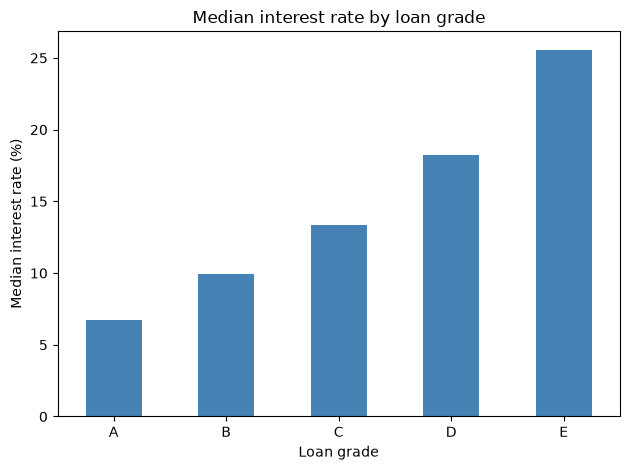

In [70]:
ax = grade_summary.plot.bar(
    x="grade",
    y="median_interest_rate",
    legend=False,
    color="steelblue",
)
ax.set_title("Median interest rate by loan grade")
ax.set_xlabel("Loan grade")
ax.set_ylabel("Median interest rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The chart is based on five summary rows rather than all 50 original rows. The transformation determines the meaning of each bar.

**Question 8:** Plot the median loan amount for each homeownership group from your Question 7 summary. Add a descriptive title and readable axis labels. What does one bar represent?

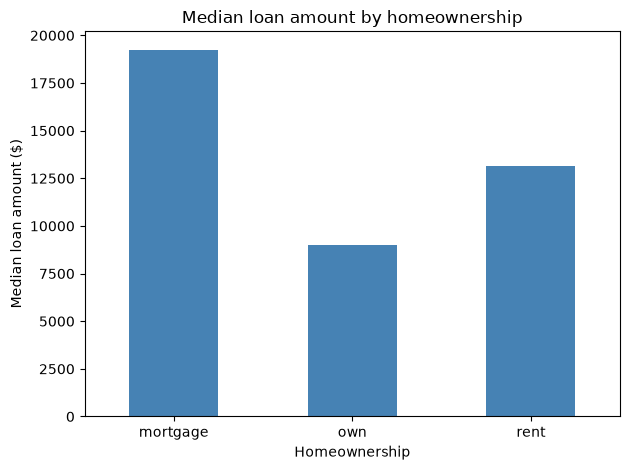

In [71]:
ax = homeownership_summary.plot.bar(
    x="homeownership",
    y="median_loan_amount",
    legend=False,
    color="steelblue",
)

ax.set_title("Median loan amount by homeownership")
ax.set_xlabel("Homeownership")
ax.set_ylabel("Median loan amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Answer:** One bar represents the median loan amount for one homeownership group.




## VIII. Reshape with `pivot_table()`

**Reshaping** changes how variables are arranged in rows and columns. It does not necessarily change the underlying information.

`pd.pivot_table()` can calculate a summary for every combination of two categorical variables:

- `index` supplies the row categories;
- `columns` supplies the column categories;
- `values` identifies the numerical variable to summarize; and
- `aggfunc` identifies the summary function.


In [72]:
grade_ownership_interest = pd.pivot_table(
    loans,
    index="grade",
    columns="homeownership",
    values="interest_rate",
    aggfunc="mean",
)

grade_ownership_interest

homeownership,mortgage,own,rent
grade,,,
A,6.308571,NaN,7.16625
B,10.084000,9.43,10.47500
C,12.985000,15.04,16.02000
D,20.290000,17.09,17.67250
E,25.575000,NaN,NaN


The result is a **wide** table: each homeownership category has its own column. A missing value means the sample contains no observation for that combination.

**Question:** How does this output compare to the following?

In [73]:
pd.crosstab(loans["grade"], loans["homeownership"])

homeownership,mortgage,own,rent
grade,,,
A,7,0,8
B,10,1,8
C,4,1,1
D,3,1,4
E,2,0,0


In [74]:
pd.crosstab(
    loans["grade"],
    loans["homeownership"],
    values=loans["interest_rate"],
    aggfunc="mean",
)

homeownership,mortgage,own,rent
grade,,,
A,6.308571,NaN,7.16625
B,10.084000,9.43,10.47500
C,12.985000,15.04,16.02000
D,20.290000,17.09,17.67250
E,25.575000,NaN,NaN


**Question 9:** Create a pivot table showing the median `loan_amount` for each combination of `verified_income` in the rows and `term` in the columns. Explain what one cell represents.

Use the next cell for your code.


In [75]:
verified_income_term = pd.pivot_table(
    loans,
    index="verified_income",
    columns="term",
    values="loan_amount",
    aggfunc="median",
)

verified_income_term

term,36,60
verified_income,,
Not Verified,11000.0,22000.0
Source Verified,12800.0,18200.0
Verified,20000.0,36750.0


**Answer:** One cell represents the median loan amount for borrowers with a specific verified income category and loan term.



<br><br><br>


## IX. Reshape wide data with `melt()`

Many plotting and analysis functions work best when each variable has one column and each observation or summary has one row. This arrangement is often called **long** or **tidy** data.

First, `.reset_index()` turns the pivot table's row labels into a column. Then `.melt()` gathers the separate homeownership columns into two columns: a category column and a value column.

The final `.dropna()` removes rows whose reshaped summary value is missing.


In [76]:
# Previous code used pivot_table to create a wide format table. Now we will use melt to convert it to long format.
grade_ownership_interest = pd.pivot_table(
    loans,
    index="grade",
    columns="homeownership",
    values="interest_rate",
    aggfunc="mean",
)

grade_ownership_interest.reset_index().head()

homeownership,grade,mortgage,own,rent
0,A,6.308571,NaN,7.16625
1,B,10.084000,9.43,10.47500
2,C,12.985000,15.04,16.02000
3,D,20.290000,17.09,17.67250
4,E,25.575000,NaN,NaN


In [77]:
# Convert the wide format table to long format using melt
grade_ownership_long = (
    grade_ownership_interest.reset_index()
    .melt(
        id_vars="grade",
        var_name="homeownership",
        value_name="mean_interest_rate",
    )
    .dropna()
)

grade_ownership_long

,grade,homeownership,mean_interest_rate
0,A,mortgage,6.308571
1,B,mortgage,10.084000
2,C,mortgage,12.985000
3,D,mortgage,20.290000
4,E,mortgage,25.575000
6,B,own,9.430000
7,C,own,15.040000
8,D,own,17.090000
10,A,rent,7.166250
11,B,rent,10.475000


In `.melt()`:

- `id_vars` identifies columns that stay fixed;
- `var_name` names the new column containing the former column headings; and
- `value_name` names the new column containing the cell values.


### Choose a table shape for the graph

Long form is useful when a plotting function expects one column for the group and one column for the value. However, pandas' Matplotlib-backed `.plot.bar()` method creates a grouped bar chart most simply from the original wide pivot table: each numerical column becomes one bar series. Therefore, this particular graph does not need the long table. Long form will become especially useful with later plotting libraries that map a grouping column directly to color or other visual properties.


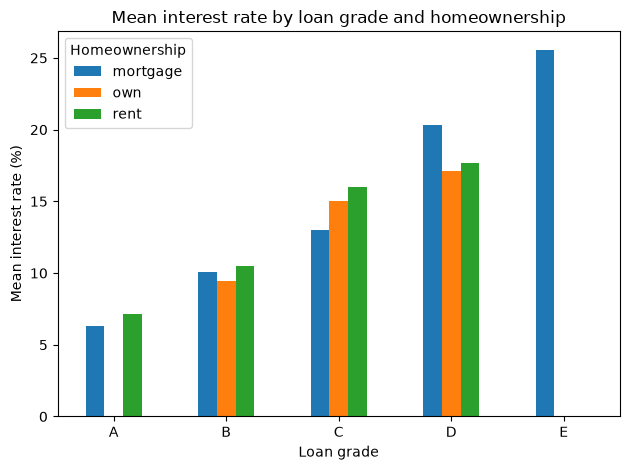

In [78]:
ax = grade_ownership_interest.plot.bar()
ax.set_title("Mean interest rate by loan grade and homeownership")
ax.set_xlabel("Loan grade")
ax.set_ylabel("Mean interest rate (%)")
ax.legend(title="Homeownership")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Question 10:** Convert your Question 9 pivot table from wide to long form. Name the gathered category column `term` and the values column `median_loan_amount`. Remove rows with missing values. 


In [79]:
verified_income_term_long = (
    verified_income_term.reset_index()
    .melt(
        id_vars="verified_income",
        var_name="term",
        value_name="median_loan_amount",
    )
    .dropna()
)

verified_income_term_long

,verified_income,term,median_loan_amount
0,Not Verified,36,11000.0
1,Source Verified,36,12800.0
2,Verified,36,20000.0
3,Not Verified,60,22000.0
4,Source Verified,60,18200.0
5,Verified,60,36750.0


**Answer:** Each row now shows a verified income category, a loan term, and the median loan amount. Rows with missing values are removed.




## X. Put the workflow together

The next analysis starts with the original loan table and ends with a plot-ready summary. Read the chain from top to bottom:

- keep loans with reported employment length;
- create a loan-to-income percentage;
- group by loan grade;
- calculate summaries;
- sort by grade; and
- return the group label to a regular column.

`.dropna(subset=["emp_length"])` removes only rows where `emp_length` is missing. The `subset` argument identifies which column pandas should check.


In [80]:
# Create a summary of loan risk by grade, including the number of loans, median loan-to-income percentage, and median interest rate.
grade_risk_summary = (
    loans.dropna(subset=["emp_length"])
    .assign(
        loan_to_income_percent=(loans["loan_amount"] / loans["annual_income"] * 100)
    )
    .groupby("grade", as_index=False)
    .agg(
        number_of_loans=("loan_amount", "size"),
        median_loan_to_income_percent=("loan_to_income_percent", "median"),
        median_interest_rate=("interest_rate", "median"),
    )
    .sort_values("grade")
)

grade_risk_summary

,grade,number_of_loans,median_loan_to_income_percent,median_interest_rate
0,A,14,15.857143,6.710
1,B,19,14.285714,9.930
2,C,6,23.593750,13.350
3,D,8,21.469163,18.255
4,E,1,30.000000,24.850


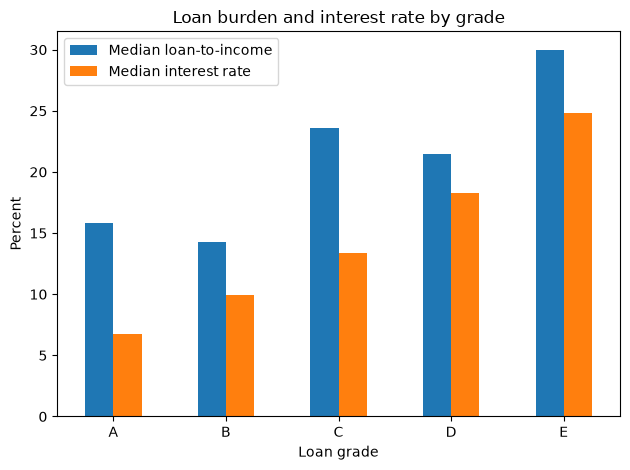

In [81]:
# Create a bar plot to visualize the median loan-to-income percentage and median interest rate by loan grade.
ax = grade_risk_summary.plot(
    x="grade",
    y=["median_loan_to_income_percent", "median_interest_rate"],
    kind="bar",
)
ax.set_title("Loan burden and interest rate by grade")
ax.set_xlabel("Loan grade")
ax.set_ylabel("Percent")
ax.legend(["Median loan-to-income", "Median interest rate"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Because both plotted summaries are percentages, they can share an axis, but they measure different concepts. A chart should make that distinction clear.

**Question 11:** Build a complete workflow that:

- keeps loans with `debt_to_income` below 1;
- creates `credit_utilization_percent`;
- groups by `homeownership`;
- calculates the number of loans and median credit-utilization percentage;
- sorts the summary from highest to lowest median utilization; and
- creates a labeled bar chart of the median utilization.

Use the next cell for your code.


In [82]:
credit_summary = (
    loans[loans["debt_to_income"] < 1]
    .assign(
        credit_utilization_percent=
        loans["total_credit_utilized"] / loans["total_credit_limit"] * 100
    )
    .groupby("homeownership", as_index=False)
    .agg(
        number_of_loans=("loan_amount", "size"),
        median_credit_utilization_percent=("credit_utilization_percent", "median"),
    )
    .sort_values(
        by="median_credit_utilization_percent",
        ascending=False
    )
)

credit_summary

,homeownership,number_of_loans,median_credit_utilization_percent
1,own,3,45.821727
2,rent,16,41.317246
0,mortgage,23,14.313128


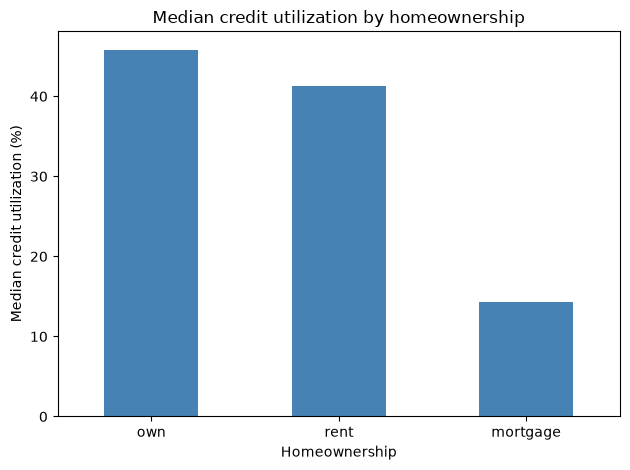

In [83]:
ax = credit_summary.plot.bar(
    x="homeownership",
    y="median_credit_utilization_percent",
    legend=False,
    color="steelblue",
)

ax.set_title("Median credit utilization by homeownership")
ax.set_xlabel("Homeownership")
ax.set_ylabel("Median credit utilization (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Describe the comparison shown by your chart, identify what one bar represents, and state one limitation of using this sample. Write 3-5 sentences.

**Answer:** The chart shows that borrowers who own their home have the highest median credit utilization, followed by renters, while borrowers with a mortgage have the lowest. One bar represents the median credit utilization percentage for one homeownership group.



<br><br><br>

### Check your work

One valid transformation and plot appear below.


In [84]:
ownership_utilization_summary = (
    loans.loc[loans["debt_to_income"] < 1]
    .assign(
        credit_utilization_percent=(
            loans["total_credit_utilized"] / loans["total_credit_limit"] * 100
        )
    )
    .groupby("homeownership")
    .agg(
        number_of_loans=("loan_amount", "size"),
        median_credit_utilization_percent=(
            "credit_utilization_percent",
            "median",
        ),
    )
    .reset_index()
    .sort_values(
        "median_credit_utilization_percent",
        ascending=False,
    )
)

ownership_utilization_summary

,homeownership,number_of_loans,median_credit_utilization_percent
1,own,3,45.821727
2,rent,16,41.317246
0,mortgage,23,14.313128


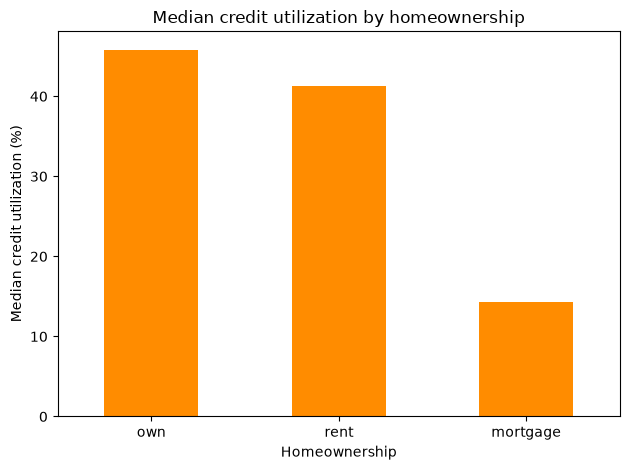

In [85]:
ax = ownership_utilization_summary.plot.bar(
    x="homeownership",
    y="median_credit_utilization_percent",
    legend=False,
    color="darkorange",
)
ax.set_title("Median credit utilization by homeownership")
ax.set_xlabel("Homeownership")
ax.set_ylabel("Median credit utilization (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## XI. Independent investigation

**Question 12:** Pose and investigate one defensible question using `loan50.csv`. Your workflow must include:

- at least one filter;
- at least one derived column;
- a grouped summary or pivot table;
- a sort that supports interpretation; and
- one labeled plot based on the prepared table.

Do not repeat a question already answered in the lab.

**Your investigation question:** Among borrowers with an annual income of at least $50,000, how does the median loan-to-income percentage differ by loan purpose?



Use the next cell for your work. You may add more cells.


In [86]:
loan_purpose_summary = (
    loans[loans["annual_income"] >= 50000]
    .assign(
        loan_to_income_percent=
        loans["loan_amount"] / loans["annual_income"] * 100
    )
    .groupby("loan_purpose", as_index=False)
    .agg(
        number_of_loans=("loan_amount", "size"),
        median_loan_to_income_percent=("loan_to_income_percent", "median"),
    )
    .sort_values(
        by="median_loan_to_income_percent",
        ascending=False
    )
)

loan_purpose_summary

,loan_purpose,number_of_loans,median_loan_to_income_percent
2,debt_consolidation,19,23.125000
0,car,2,20.026408
5,small_business,1,20.000000
4,other,4,15.034562
1,credit_card,12,12.527473
3,home_improvement,4,9.921260


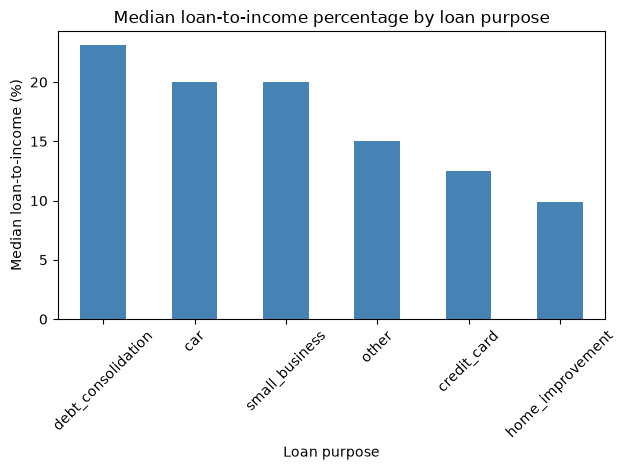

In [87]:
ax = loan_purpose_summary.plot.bar(
    x="loan_purpose",
    y="median_loan_to_income_percent",
    legend=False,
    color="steelblue",
)

ax.set_title("Median loan-to-income percentage by loan purpose")
ax.set_xlabel("Loan purpose")
ax.set_ylabel("Median loan-to-income (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Answer your investigation question using specific evidence. Explain the meaning of one plotted mark, describe one pattern, and state one limitation. Write 4-6 sentences.

**Answer:** Among borrowers earning at least $50,000, debt consolidation loans have the highest median loan-to-income percentage at about 23.1%. Car loans are next at about 20.0%, while home improvement loans have the lowest at about 9.9%. One bar represents the median loan-to-income percentage for one loan purpose. The general pattern shows that debt consolidation loans take up a larger percentage of borrowers' annual income than most other loan purposes.




## XII. Submission check

Before exporting:

- Add your name and date, and complete Questions 1-12.
- Confirm that every transformation supports the stated question and every plot is labeled.
- Restart the kernel, run all cells, and resolve any errors.
- Export to HTML and confirm that all work and Check your work sections are visible.
